In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA


## ARIMA

ARIMA - a statistical model to predict future based on pattern in historical data

AR = AutoRegressive         - Future value depends on past value    - PACF plot
I  = Integrated             - Stationary Data                       - ADF Test
MA = Moving Average         - Average of past error                 - ACF plot

AR = AutoCorrelation + Regressive

ARIMA parameters (p,d,q)


In [3]:
sp500 = yf.download("SPY", period="5y")["Close"]["SPY"]

sp500 = sp500.asfreq("B") 
sp500 = sp500.ffill()  

adf_test = adfuller(sp500)
print(f"ADF Statistic: {adf_test[0]:.2f}")
print(f"P-value      : {adf_test[1]:.2f}")

[*********************100%***********************]  1 of 1 completed

ADF Statistic: -0.15
P-value      : 0.94


In [4]:
sp500_returns = sp500.pct_change(fill_method=None).dropna()

adf_test = adfuller(sp500_returns)
print(f"ADF Statistic: {adf_test[0]:.2f}")
print(f"P-value      : {adf_test[1]:.2f}")


ADF Statistic: -12.03
P-value      : 0.00


### Find p using PACF

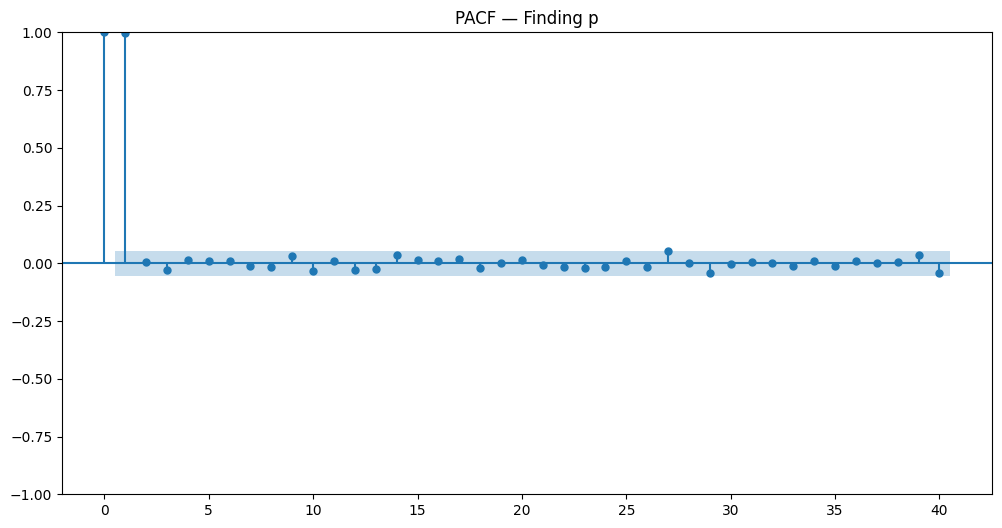

In [5]:
fig, ax = plt.subplots(figsize=(12,6))
plot_pacf(sp500, lags=40, ax = ax)
ax.set_title("PACF — Finding p")
plt.show()

Ignore first spike (Lag 0)
Lag 1 = spike outside blue - 1 is significant
So p is 1

Only 1 past price significantly influences today's price


### Find q using ACF

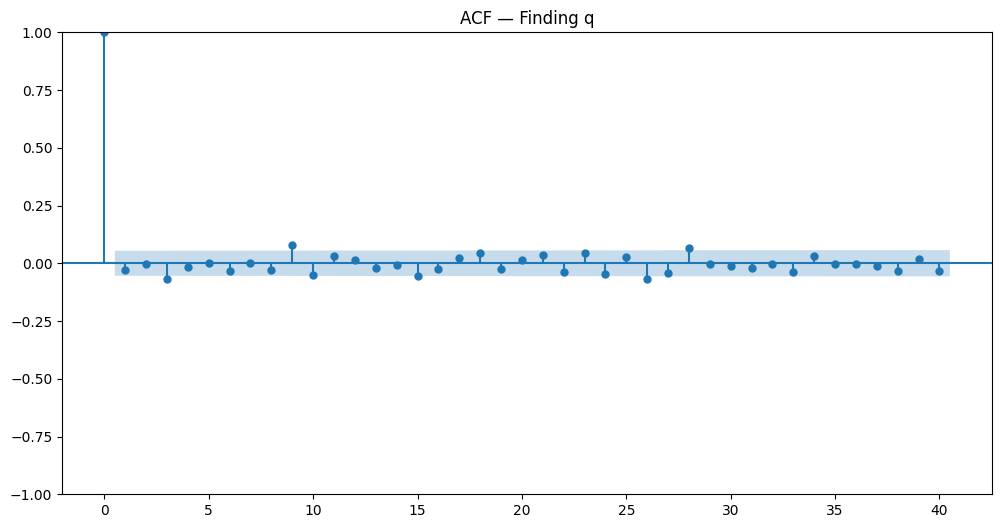

In [6]:
fig, ax = plt.subplots(figsize=(12,6))
plot_acf(sp500_returns, lags=40, ax=ax)
ax.set_title("ACF — Finding q")
plt.show()

### ARIMA

In [7]:
model = ARIMA(sp500, order = (1,1,1))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                    SPY   No. Observations:                 1305
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -3913.242
Date:                Sat, 14 Mar 2026   AIC                           7832.484
Time:                        21:29:30   BIC                           7848.004
Sample:                    03-15-2021   HQIC                          7838.306
                         - 03-13-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4924      0.402     -1.224      0.221      -1.281       0.296
ma.L1          0.4527      0.409      1.107      0.268      -0.349       1.255
sigma2        23.6656      0.359     65.988      0.0

p and q is not significant so has weak influence

ar.L1 and ma.L1

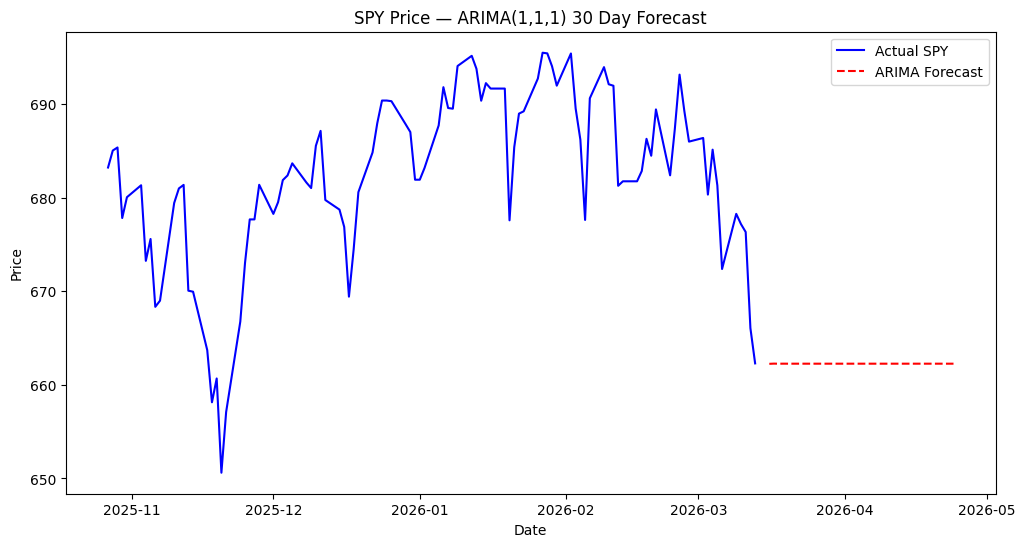

In [8]:

forecast = model_fit.forecast(steps=30)

last_date = sp500.index[-1]
future_dates = pd.bdate_range(start=last_date, periods=31)[1:]  # business days

# Plot
plt.figure(figsize=(12,6))
plt.plot(sp500.index[-100:], sp500.values[-100:], label="Actual SPY", color="blue")
plt.plot(future_dates, forecast, label="ARIMA Forecast", color="red", linestyle="--")
plt.title("SPY Price — ARIMA(1,1,1) 30 Day Forecast")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()